# The Brazilian factors, original and orthogonal

The seven local factors of the companion repository, [brazil-equity-factors](https://github.com/pedroandion/brazil-equity-factors), before and after the SW/L transformation of [`01_paper_replication`](01_paper_replication.ipynb).

| Factor | Long minus short |
|---|---|
| `Mkt_RF` | Ibovespa minus the SELIC rate |
| `SMB` | small minus big market value |
| `HML` | high minus low book-to-price |
| `RMW` | high minus low gross profit over total assets |
| `CMA` | low minus high growth of total assets |
| `WML` | winners minus losers over the last 12 months, skipping the last one |
| `BAB` | low beta minus high beta |

Except for the market, each factor is the top 30% minus the bottom 30% of the investable universe on its signal, with equal weights, rebalanced on the first business day of each month (notebook `03_historical_betas` of the companion). BAB is not levered to a zero beta, so it is short the market.

When these factors were used in a portfolio construction project, BAB had to be dropped: its correlation with the market made the factor model unstable. The transformation keeps all seven factors and splits the systematic risk among them without ambiguity. This notebook looks at how much the factors overlap and at what the orthogonal factors are.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor

from orthofactors.data import load_brazil_factors, to_monthly, BRAZIL_FACTORS, MONTHLY_SAMPLE
from orthofactors.orthogonalization import (orthogonalize_swl, orthogonalize_swl_correlation, orthogonalize_pca,
                                            orthogonalize_gs, calculate_frobenius_norm)
from orthofactors.plotting import set_style, factor_colors, DIVERGING

set_style()
Path('results').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

## Data

Daily returns from 2010-01-05, when BAB starts, to 2026-07-23. The monthly returns compound the daily ones, as the companion does, and keep the full months, February 2010 to June 2026.

In [2]:
daily = load_brazil_factors()[BRAZIL_FACTORS]
monthly = to_monthly(daily).loc[MONTHLY_SAMPLE]
print(f'Daily: {len(daily)} days, {daily.index[0]:%Y-%m-%d} to {daily.index[-1]:%Y-%m-%d}')
print(f'Monthly: {len(monthly)} months, {monthly.index[0]:%Y-%m} to {monthly.index[-1]:%Y-%m}')

Daily: 4157 days, 2010-01-05 to 2026-07-23
Monthly: 197 months, 2010-02 to 2026-06


In [3]:
# Annualized mean and volatility, Sharpe ratio and t-statistic of the mean, from monthly returns
def moments(returns):
    return pd.DataFrame({'Mean': returns.mean() * 12, 'Volatility': returns.std() * np.sqrt(12),
                         'Sharpe ratio': returns.mean() / returns.std() * np.sqrt(12),
                         't-statistic': returns.mean() / returns.std() * np.sqrt(len(returns))})

moments(monthly).style.format({'Mean': '{:.2%}', 'Volatility': '{:.2%}', 'Sharpe ratio': '{:.2f}', 't-statistic': '{:.2f}'})

,Mean,Volatility,Sharpe ratio,t-statistic
Mkt_RF,-1.33%,20.67%,-0.06,-0.26
SMB,-4.28%,15.30%,-0.28,-1.13
HML,-1.30%,16.92%,-0.08,-0.31
RMW,4.06%,13.21%,0.31,1.25
CMA,0.16%,11.67%,0.01,0.06
WML,16.92%,18.58%,0.91,3.69
BAB,3.37%,23.54%,0.14,0.58


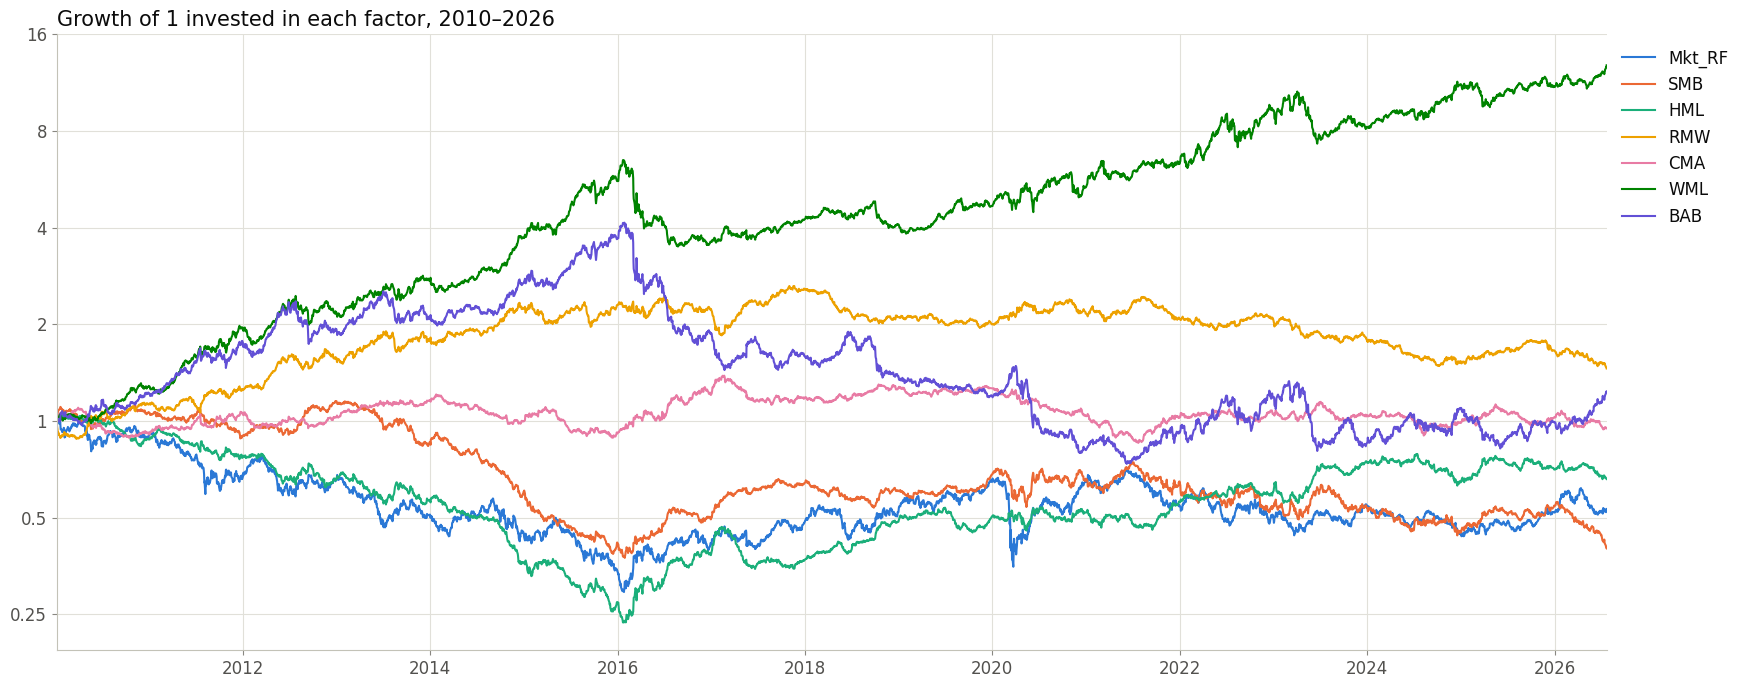

In [4]:
# Cumulative return of each factor, log scale
fig, ax = plt.subplots()
for factor in BRAZIL_FACTORS:
    ax.plot(daily.index, daily[factor].add(1).cumprod(), color = colors[factor], label = factor)
ax.set_yscale('log')
ax.set_yticks([0.25, 0.5, 1, 2, 4, 8, 16])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{y:g}'))
ax.yaxis.set_minor_locator(ticker.NullLocator())
ax.margins(x = 0)
ax.set_title('Growth of 1 invested in each factor, 2010–2026')
ax.legend(loc = 'upper left', bbox_to_anchor = (1.0, 1.0))
plt.show()

Over these 16 years the market lost to the SELIC rate, by 1.3% a year, and only momentum has a clearly positive premium: 16.9% a year, with a t-statistic of 3.7. Profitability (4.1%) and BAB (3.4%) are positive but not significant, and size and value are negative. These are in-sample means of single-sort portfolios without costs, so they say little about premia in general. What matters here is how the factors move together.

## How much the factors overlap

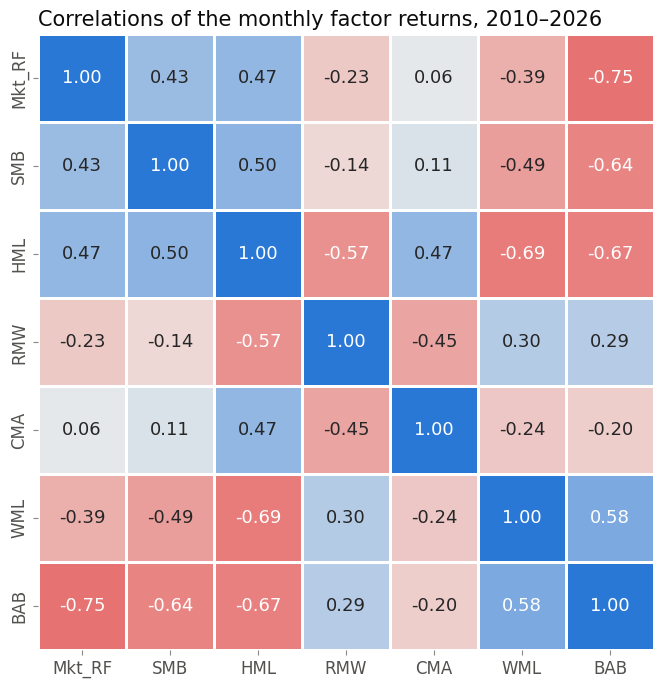

In [5]:
fig, ax = plt.subplots(figsize = (10, 8))
sns.heatmap(monthly.corr().round(2) + 0.0, annot = True, fmt = '.2f', cmap = DIVERGING, vmin = -1, vmax = 1, square = True,
            cbar = False, linewidths = 2, linecolor = 'white', annot_kws = {'size': 13}, ax = ax)
ax.set_title('Correlations of the monthly factor returns, 2010–2026')
ax.grid(False)
plt.show()

In [6]:
# Variance inflation factors, with and without BAB, monthly and daily
def vif(factors):
    X = factors.assign(const = 1.0).values
    return pd.Series([variance_inflation_factor(X, i) for i in range(factors.shape[1])], index = factors.columns)

pd.DataFrame({'Monthly, 7 factors': vif(monthly), 'Monthly, without BAB': vif(monthly.drop(columns = 'BAB')),
              'Daily, 7 factors': vif(daily), 'Daily, without BAB': vif(daily.drop(columns = 'BAB'))}).reindex(BRAZIL_FACTORS).round(2)

,"Monthly, 7 factors","Monthly, without BAB","Daily, 7 factors","Daily, without BAB"
Mkt_RF,2.43,1.42,2.02,1.18
SMB,1.81,1.56,1.57,1.37
HML,3.67,3.38,2.53,2.34
RMW,1.66,1.65,1.48,1.48
CMA,1.44,1.44,1.24,1.24
WML,2.06,2.03,1.87,1.73
BAB,4.06,NaN,3.46,NaN


In [7]:
# Eigenvalues of the correlation matrix: the share of the total variance of the standardized factors along each axis
eigenvalues = np.linalg.eigvalsh(monthly.corr())[::-1]
pd.DataFrame({'Eigenvalue': eigenvalues, 'Share': eigenvalues / eigenvalues.sum()},
             index = [f'PC{i + 1}' for i in range(len(eigenvalues))]).T.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Eigenvalue,3.596,1.332,0.684,0.542,0.463,0.218,0.166
Share,0.514,0.190,0.098,0.077,0.066,0.031,0.024


The factors overlap much more than the US factors of the paper, whose largest correlation was 0.65. BAB is the most connected: −0.75 with the market, −0.67 with HML, −0.64 with SMB and +0.58 with WML. Being long low-beta and short high-beta stocks, it is short the market, and in Brazil the low-beta stocks have also been the bigger, more expensive ones with stronger momentum. Value is the other hub, with −0.69 against momentum and −0.57 against profitability.

BAB has the largest variance inflation factor, 4.1 in monthly data, and dropping it brings the market's from 2.4 to 1.4: that is the instability that led to dropping BAB before. The first principal component holds half of the variance of the standardized factors, and the smallest eigenvalue is 22 times smaller than the largest.

## The orthogonal factors

In [8]:
monthly_ortho, S, Psi = orthogonalize_swl(monthly, return_matrices = True)
daily_ortho, _, Psi_daily = orthogonalize_swl(daily, return_matrices = True)

pd.Series({'Largest correlation between two orthogonal factors': (monthly_ortho.corr() - np.eye(7)).abs().max().max(),
           'Largest relative change of a volatility': (monthly_ortho.std() / monthly.std() - 1).abs().max()})

Largest correlation between two orthogonal factors    1.305934e-15
Largest relative change of a volatility               7.771561e-16
dtype: float64

In [9]:
# Resemblance: correlation of each factor with its orthogonal version
resemblance = pd.DataFrame({'Monthly': np.diag(Psi), 'Daily': np.diag(Psi_daily)}, index = BRAZIL_FACTORS)
resemblance.T.round(3)

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
Monthly,0.883,0.883,0.801,0.921,0.937,0.889,0.841
Daily,0.933,0.928,0.834,0.933,0.960,0.906,0.854


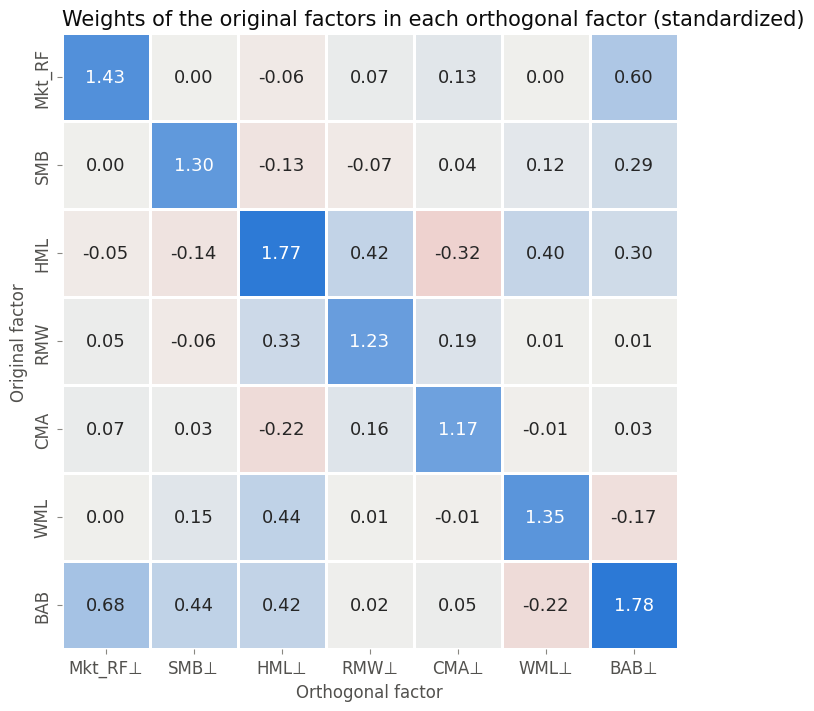

In [10]:
# What each orthogonal factor is made of: column k holds the weights of the standardized original factors
# in the standardized orthogonal factor k, that is diag(σ) S diag(1/σ)
composition = S.mul(monthly.std(), axis = 0).div(monthly.std(), axis = 1)

fig, ax = plt.subplots(figsize = (11, 8))
sns.heatmap(composition.round(2) + 0.0, annot = True, fmt = '.2f', cmap = DIVERGING, center = 0, vmin = -1.8, vmax = 1.8,
            square = True, cbar = False, linewidths = 2, linecolor = 'white', annot_kws = {'size': 13}, ax = ax)
ax.set_xticklabels([f'{f}⊥' for f in BRAZIL_FACTORS])
ax.set_xlabel('Orthogonal factor')
ax.set_ylabel('Original factor')
ax.set_title('Weights of the original factors in each orthogonal factor (standardized)')
ax.grid(False)
plt.show()

The resemblance is high, but lower than in the paper: from 0.80 (HML) to 0.94 (CMA) in monthly data, and from 0.83 to 0.96 in daily data, where the factors are less correlated. The heatmap shows why. To remove the overlap, each orthogonal factor adds the factors it was negatively correlated with and subtracts the ones it was positively correlated with:

- **Mkt_RF⊥** adds BAB (0.68). Since BAB is short the market, the orthogonal market is the market without its low-beta tilt.
- **BAB⊥** adds the market (0.60), SMB (0.29) and HML (0.30). It is the low-beta bet without its short market position.
- **HML⊥** adds momentum (0.44), BAB (0.42) and profitability (0.33). It is value without its bets against winners, low-beta and profitable firms.

## The premia change

In [11]:
# Annualized means of the original and the orthogonal factors, with their t-statistics, and the t-statistic of the
# mean difference, a paired test like the one in the paper
difference = monthly_ortho - monthly
premia = pd.DataFrame({'Original': monthly.mean() * 12, 't original': moments(monthly)['t-statistic'],
                       'Orthogonal': monthly_ortho.mean() * 12, 't orthogonal': moments(monthly_ortho)['t-statistic'],
                       't of the difference': difference.mean() / difference.std() * np.sqrt(len(difference))})
premia.style.format({'Original': '{:.2%}', 'Orthogonal': '{:.2%}', 't original': '{:.2f}', 't orthogonal': '{:.2f}',
                     't of the difference': '{:.2f}'})

,Original,t original,Orthogonal,t orthogonal,t of the difference
Mkt_RF,-1.33%,-0.26,0.53%,0.10,0.75
SMB,-4.28%,-1.13,-2.65%,-0.70,0.89
HML,-1.30%,-0.31,7.81%,1.87,3.46
RMW,4.06%,1.25,4.99%,1.53,0.72
CMA,0.16%,0.06,0.91%,0.32,0.73
WML,16.92%,3.69,21.05%,4.59,1.92
BAB,3.37%,0.58,-0.98%,-0.17,-1.33


The premia change, as in the paper. HML⊥ earns 7.8% a year against −1.3% for HML, and the difference is significant (t-statistic of 3.5). BAB⊥ earns −1.0% against +3.4%, and WML⊥ 21.1% against 16.9%. The heatmap explains these moves: HML⊥ holds a share of momentum, the factor with the largest premium, and BAB⊥ holds a share of the market, which lost to the SELIC.

So the orthogonal premia mix the premia of the factors that make up each orthogonal factor. They are a by-product, not the point: the transformation is for splitting risk, and the next notebooks use it that way.

## SW/L against PCA and Gram-Schmidt

The same comparison as Table 1 of the paper, with all seven factors at once. Gram-Schmidt depends on the order: a factor placed first stays unchanged, and the later it comes, the more it changes, so the table shows each factor in the last position.

In [12]:
pca = orthogonalize_pca(monthly)
gs_last = {f: orthogonalize_gs(monthly, [g for g in BRAZIL_FACTORS if g != f] + [f])[f] for f in BRAZIL_FACTORS}
correlation_version = orthogonalize_swl_correlation(monthly)

comparison = pd.DataFrame({'SW/L': resemblance['Monthly'],
                           'SW/L, correlation version': [monthly[f].corr(correlation_version[f]) for f in BRAZIL_FACTORS],
                           'PCA': [monthly[f].corr(pca[f]) for f in BRAZIL_FACTORS],
                           'Gram-Schmidt, factor last': [monthly[f].corr(gs_last[f]) for f in BRAZIL_FACTORS]},
                          index = BRAZIL_FACTORS)
comparison.T.round(3)

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
SW/L,0.883,0.883,0.801,0.921,0.937,0.889,0.841
"SW/L, correlation version",0.888,0.907,0.803,0.931,0.950,0.887,0.801
PCA,0.475,0.295,0.352,0.582,0.485,0.372,0.937
"Gram-Schmidt, factor last",0.642,0.743,0.522,0.777,0.832,0.697,0.497


In [13]:
# Frobenius norm of the deviation from the original factors, in percent, with Gram-Schmidt in the order of the table
pd.Series({'SW/L': calculate_frobenius_norm(monthly * 100, monthly_ortho * 100),
           'PCA': calculate_frobenius_norm(monthly * 100, pca * 100),
           'Gram-Schmidt': calculate_frobenius_norm(monthly * 100, orthogonalize_gs(monthly, BRAZIL_FACTORS) * 100)}).round(1)

SW/L             97.0
PCA             178.0
Gram-Schmidt    129.6
dtype: float64

In [14]:
# The covariance and the correlation versions of SW/L give almost the same factors here
pd.Series({f: monthly_ortho[f].corr(correlation_version[f]) for f in BRAZIL_FACTORS}).round(4)

Mkt_RF    0.9994
SMB       0.9982
HML       0.9976
RMW       0.9992
CMA       0.9989
WML       0.9995
BAB       0.9969
dtype: float64

SW/L keeps every factor recognizable, and PCA does not. Its components are combinations of all the factors, and only one resembles its factor closely (BAB, 0.94), while size keeps a correlation of 0.30 with the component matched to it. Gram-Schmidt keeps the first factor intact but changes the last one more than SW/L changes any factor: placed last, BAB keeps a correlation of 0.50 with the original. The total deviation is 97 for SW/L, 178 for PCA and 130 for Gram-Schmidt in the order of the table.

The covariance version of the paper and the correlation version, which does not depend on the scale of each factor, give factors with correlations of 0.997 or more with each other. So the scale of BAB, which is not levered, does not drive the results here.

In [15]:
moments(monthly).join(resemblance).round(4).to_csv('results/brazil_factors.csv')
premia.round(4).to_csv('results/brazil_premia.csv')